# E-Commerce Transaction Fraud Detection Using Machine Learning and Behavioral Analytics
### MBA Data Science & Data Analytics Applied Capstone Project

**Course & Specialization:** MBA in Data Science & Business Analytics  
**Academic Title:** E-Commerce Transaction Fraud Detection Using Machine Learning and Behavioral Analytics  
**Primary Dataset:** `Fraud_Data.csv` (151,112 transaction records)  
**Auxiliary Geolocation Dataset:** `IpAddress_to_Country.csv` (138,846 IP ranges)  
**Execution Environment:** Python 3.13 | scikit-learn, XGBoost, CatBoost, SHAP, imbalanced-learn  

---

## Project Structure Overview

This notebook follows the complete fraud detection workflow from data checking and exploratory analysis to machine learning, model evaluation, explainability, anomaly detection, and fraud risk scoring.

1. **Environment Setup**
2. **Dataset Loading & Data Quality Check**
3. **Mapping IP Addresses to Countries**
4. **Fraud vs. Legitimate Transactions**
5. **Purchase Amount & Customer Age Analysis**
6. **Source & Browser Analysis**
7. **Country Analysis**
8. **Signup-to-Purchase Time Analysis**
9. **Device & IP Reuse Analysis**
10. **Statistical Tests & Feature Relationships**
11. **Train-Test Split & Behavioral Feature Engineering**
12. **Data Preprocessing**
13. **Handling Class Imbalance**
14. **Comparing Machine Learning Models**
15. **Model Evaluation: ROC & Precision-Recall Curves**
16. **XGBoost Hyperparameter Tuning**
17. **Choosing the Decision Threshold**
18. **Confusion Matrix Analysis**
19. **Understanding Important Features**
20. **SHAP: Overall Feature Impact**
21. **SHAP: Signup-to-Purchase Time & Risk**
22. **SHAP: Explaining One Prediction**
23. **Finding Unusual Transactions with Isolation Forest**
24. **Creating Three Fraud Risk Levels**
25. **Business Insights, Limitations & Conclusion**


## 1. Environment Setup

We import the libraries required for data analysis, visualization, statistical testing, machine learning, model evaluation, and model explainability.

In [1]:
import warnings
warnings.filterwarnings('ignore')

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats
from sklearn.model_selection import train_test_split, RandomizedSearchCV, StratifiedKFold
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, confusion_matrix,
    classification_report, roc_curve, precision_recall_curve
)
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier, IsolationForest
from imblearn.over_sampling import SMOTE
import xgboost as xgb
from catboost import CatBoostClassifier
import shap

# Set plotting style for inline rendering
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'Arial'
plt.rcParams['axes.edgecolor'] = '#cccccc'
plt.rcParams['axes.linewidth'] = 0.8
plt.rcParams['figure.dpi'] = 120

print("Environment successfully initialized with all core libraries.")


Environment successfully initialized with all core libraries.


## 2. Dataset Loading & Data Quality Check
We load `Fraud_Data.csv` (151,112 transaction records) and `IpAddress_to_Country.csv` (138,846 IP ranges) and check their size, missing values, duplicate records, and unique users, devices, and IP addresses.


In [2]:
# Load raw datasets
df_fraud = pd.read_csv('Fraud_Data.csv')
df_ip = pd.read_csv('IpAddress_to_Country.csv')

print(f"Fraud_Data Dimensions: {df_fraud.shape[0]:,} rows x {df_fraud.shape[1]} columns")
print(f"IpAddress_to_Country Dimensions: {df_ip.shape[0]:,} rows x {df_ip.shape[1]} columns")
print(f"Missing Values in Fraud_Data: {df_fraud.isnull().sum().sum()}")
print(f"Duplicate Rows in Fraud_Data: {df_fraud.duplicated().sum()}")
print(f"Unique Users: {df_fraud['user_id'].nunique():,} (1 transaction per user)")
print(f"Unique Devices: {df_fraud['device_id'].nunique():,} (Device sharing present)")
print(f"Unique IPs: {df_fraud['ip_address'].nunique():,} (IP sharing present)")

class_counts = df_fraud['class'].value_counts()
class_pcts = df_fraud['class'].value_counts(normalize=True) * 100
print(f"\nClass Distribution:\n  Legitimate (0): {class_counts[0]:,} ({class_pcts[0]:.2f}%)\n  Fraudulent (1): {class_counts[1]:,} ({class_pcts[1]:.2f}%)")
print(f"Imbalance Ratio: {class_counts[0] / class_counts[1]:.2f} : 1")


Fraud_Data Dimensions: 151,112 rows x 11 columns
IpAddress_to_Country Dimensions: 138,846 rows x 3 columns
Missing Values in Fraud_Data: 0
Duplicate Rows in Fraud_Data: 0
Unique Users: 151,112 (1 transaction per user)
Unique Devices: 137,956 (Device sharing present)


Unique IPs: 143,512 (IP sharing present)

Class Distribution:
  Legitimate (0): 136,961 (90.64%)
  Fraudulent (1): 14,151 (9.36%)
Imbalance Ratio: 9.68 : 1


### Interpretation

The transaction dataset contains **151,112 records**, with **0 missing values** and **0 duplicate rows**. There are **136,961 legitimate transactions (90.64%)** and **14,151 fraudulent transactions (9.36%)**, giving an imbalance ratio of **9.68:1**.

All **151,112 users are unique**, so repeated purchases by the same user cannot be studied directly. However, there are **137,956 unique devices** and **143,512 unique IP addresses**, showing that some devices and IP addresses are shared across multiple accounts.

## 3. Mapping IP Addresses to Countries

We use the IP address mapping dataset to assign a country to each transaction. Transactions that cannot be matched are marked as `Unknown`.

In [3]:
# IP range mapping via merge_asof
df_fraud['ip_address_int'] = df_fraud['ip_address'].astype(np.int64)
df_ip['lower_bound_ip_address'] = df_ip['lower_bound_ip_address'].astype(np.int64)
df_ip['upper_bound_ip_address'] = df_ip['upper_bound_ip_address'].astype(np.int64)

df_ip_sorted = df_ip.sort_values('lower_bound_ip_address').reset_index(drop=True)
df_fraud_sorted = df_fraud.sort_values('ip_address_int').reset_index(drop=True)

merged_ip = pd.merge_asof(
    df_fraud_sorted,
    df_ip_sorted,
    left_on='ip_address_int',
    right_on='lower_bound_ip_address'
)
valid_mask = merged_ip['ip_address_int'] <= merged_ip['upper_bound_ip_address']
merged_ip['country'] = np.where(valid_mask, merged_ip['country'], 'Unknown')

df_fraud = merged_ip.sort_values('user_id').reset_index(drop=True)

# Parse timestamps
df_fraud['signup_time'] = pd.to_datetime(df_fraud['signup_time'])
df_fraud['purchase_time'] = pd.to_datetime(df_fraud['purchase_time'])
df_fraud['time_diff_sec'] = (df_fraud['purchase_time'] - df_fraud['signup_time']).dt.total_seconds()

mapped_cnt = (df_fraud['country'] != 'Unknown').sum()
unknown_cnt = (df_fraud['country'] == 'Unknown').sum()
print(f"Mapped Countries: {mapped_cnt:,} ({mapped_cnt/len(df_fraud)*100:.2f}%) across {df_fraud['country'].nunique()} unique country categories")
print(f"Unmapped / Unknown Countries: {unknown_cnt:,} ({unknown_cnt/len(df_fraud)*100:.2f}%)")


Mapped Countries: 129,146 (85.46%) across 182 unique country categories
Unmapped / Unknown Countries: 21,966 (14.54%)


### Interpretation

Out of **151,112 transactions**, **129,146 (85.46%)** were mapped to a country across **182 country categories**. The remaining **21,966 transactions (14.54%)** were classified as `Unknown`.

This adds country information to the transaction data, which can be used to examine whether fraud rates differ across locations.

## 4. Fraud vs. Legitimate Transactions

We examine the distribution of legitimate and fraudulent transactions to understand the class imbalance in the dataset.

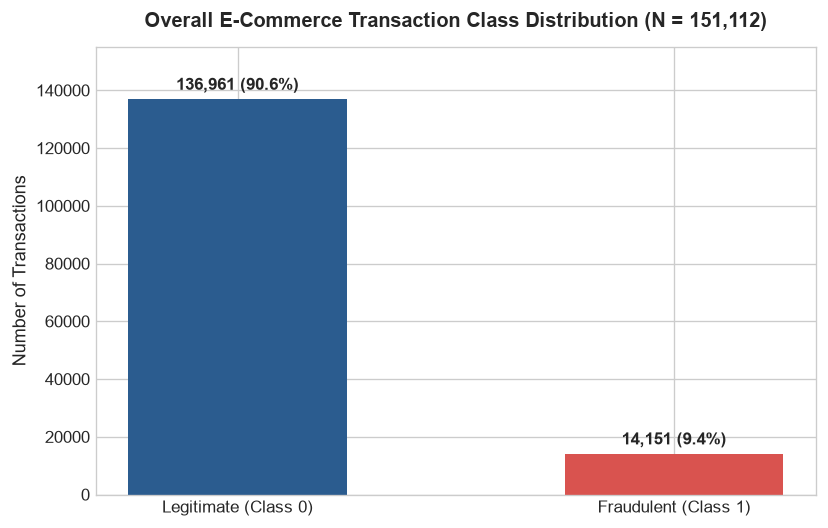

In [4]:
# Visualization 1: Class Distribution
plt.figure(figsize=(7, 4.5))
classes = ['Legitimate (Class 0)', 'Fraudulent (Class 1)']
counts = [class_counts[0], class_counts[1]]
bars = plt.bar(classes, counts, color=['#2b5c8f', '#d9534f'], width=0.5)

for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, yval + 2000,
             f"{yval:,} ({yval/sum(counts)*100:.1f}%)",
             ha='center', va='bottom', fontsize=10, fontweight='bold')

plt.title('Overall E-Commerce Transaction Class Distribution (N = 151,112)', fontsize=12, fontweight='bold', pad=12)
plt.ylabel('Number of Transactions', fontsize=11)
plt.ylim(0, 155000)
plt.tight_layout()
plt.show()


### Interpretation

Legitimate transactions account for **90.64% (136,961)** of the dataset, while fraudulent transactions account for **9.36% (14,151)**.

This means the dataset is highly imbalanced, with approximately **9.68 legitimate transactions for every 1 fraudulent transaction**. Therefore, model evaluation should consider **Precision, Recall, F1-Score, and PR-AUC**, rather than accuracy alone.

## 5. Purchase Amount & Customer Age Analysis

We compare purchase amount and customer age between legitimate and fraudulent transactions.

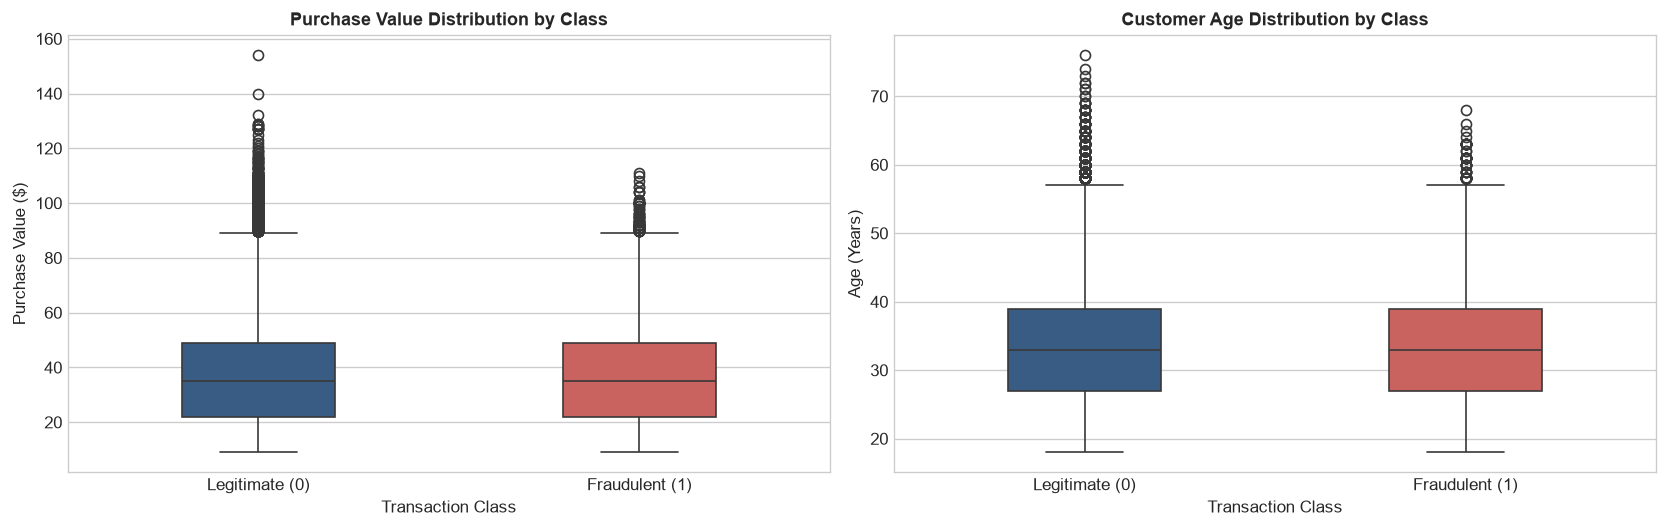

Purchase Value Summary Statistics:
            mean        std  min   50%    max
class                                        
0      36.929418  18.315064  9.0  35.0  154.0
1      36.993004  18.397654  9.0  35.0  111.0

Customer Age Summary Statistics:
            mean       std   min   50%   max
class                                       
0      33.122356  8.622678  18.0  33.0  76.0
1      33.318281  8.568001  18.0  33.0  68.0


In [5]:
# Visualization 2: Purchase Value & Age Boxplots and Distributions
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

# Purchase value boxplot
sns.boxplot(x='class', y='purchase_value', data=df_fraud, palette=['#2b5c8f', '#d9534f'], ax=axes[0], width=0.4)
axes[0].set_title('Purchase Value Distribution by Class', fontsize=11, fontweight='bold')
axes[0].set_xticklabels(['Legitimate (0)', 'Fraudulent (1)'])
axes[0].set_xlabel('Transaction Class', fontsize=10)
axes[0].set_ylabel('Purchase Value ($)', fontsize=10)

# Age boxplot
sns.boxplot(x='class', y='age', data=df_fraud, palette=['#2b5c8f', '#d9534f'], ax=axes[1], width=0.4)
axes[1].set_title('Customer Age Distribution by Class', fontsize=11, fontweight='bold')
axes[1].set_xticklabels(['Legitimate (0)', 'Fraudulent (1)'])
axes[1].set_xlabel('Transaction Class', fontsize=10)
axes[1].set_ylabel('Age (Years)', fontsize=10)

plt.tight_layout()
plt.show()

print("Purchase Value Summary Statistics:")
print(df_fraud.groupby('class')['purchase_value'].describe()[['mean', 'std', 'min', '50%', 'max']])
print("\nCustomer Age Summary Statistics:")
print(df_fraud.groupby('class')['age'].describe()[['mean', 'std', 'min', '50%', 'max']])


### Interpretation

Purchase amounts are very similar for both groups. The average purchase value is **$36.93 for legitimate transactions** and **$36.99 for fraudulent transactions**, while the median is **$35 for both groups**.

Customer age is also similar. The average age is **33.12 years for legitimate transactions** and **33.32 years for fraudulent transactions**, with a median age of **33 years for both groups**.

These results indicate that **purchase amount and age alone do not clearly separate fraudulent transactions from legitimate transactions**.

## 6. EDA: Traffic Source & Browser Analysis
We compare the observed fraud rate across marketing sources and web browsers.

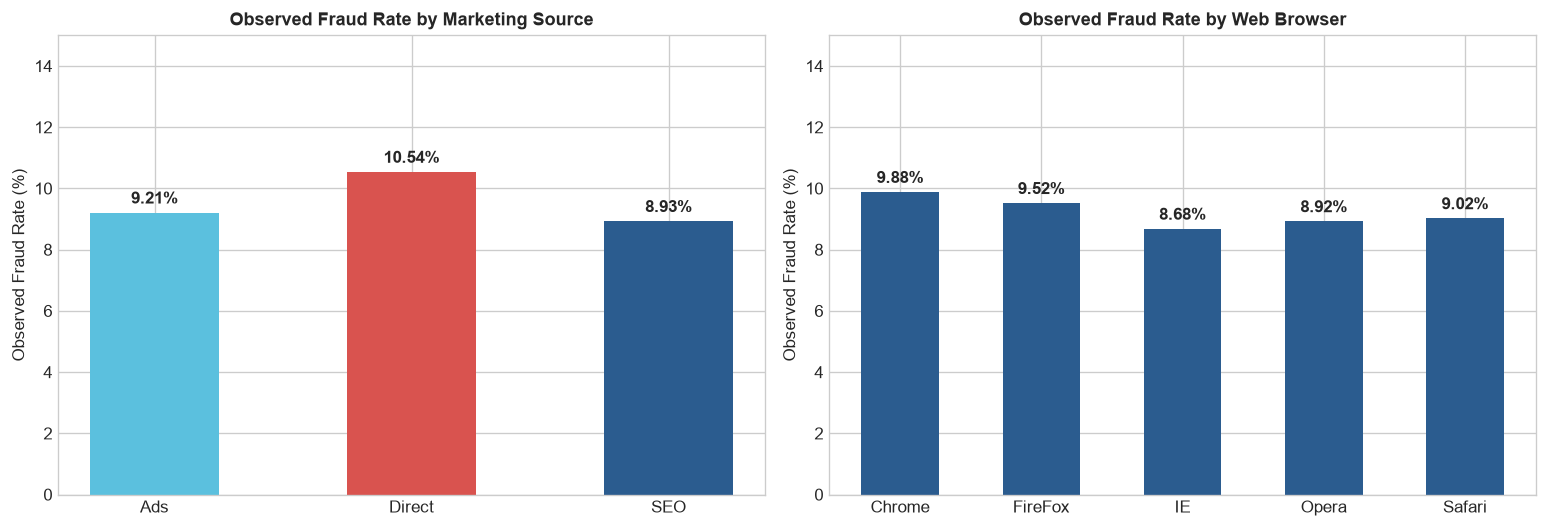

In [6]:
# Visualization 3: Source and Browser Fraud Rates
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))

# Source fraud rate
src_stats = df_fraud.groupby('source')['class'].agg(['count', 'mean']).reset_index()
src_stats['fraud_rate_pct'] = src_stats['mean'] * 100
bars1 = ax1.bar(src_stats['source'], src_stats['fraud_rate_pct'], color=['#5bc0de', '#d9534f', '#2b5c8f'], width=0.5)
ax1.set_title('Observed Fraud Rate by Marketing Source', fontsize=11, fontweight='bold')
ax1.set_ylabel('Observed Fraud Rate (%)', fontsize=10)
ax1.set_ylim(0, 15)
for bar in bars1:
    y = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width()/2.0, y + 0.3, f"{y:.2f}%", ha='center', fontweight='bold')

# Browser fraud rate
brw_stats = df_fraud.groupby('browser')['class'].agg(['count', 'mean']).reset_index()
brw_stats['fraud_rate_pct'] = brw_stats['mean'] * 100
bars2 = ax2.bar(brw_stats['browser'], brw_stats['fraud_rate_pct'], color='#2b5c8f', width=0.55)
ax2.set_title('Observed Fraud Rate by Web Browser', fontsize=11, fontweight='bold')
ax2.set_ylabel('Observed Fraud Rate (%)', fontsize=10)
ax2.set_ylim(0, 15)
for bar in bars2:
    y = bar.get_height()
    ax2.text(bar.get_x() + bar.get_width()/2.0, y + 0.3, f"{y:.2f}%", ha='center', fontweight='bold')

plt.tight_layout()
plt.show()


### Interpretation

Direct URL traffic has a slightly higher observed fraud rate of **10.54%**, compared with **9.21% for paid Ads** and **8.93% for organic SEO**.

Browser fraud rates are relatively similar, ranging from **8.68% for IE** to **9.88% for Chrome**.

The differences are relatively small, so source and browser can be used as supporting features rather than as standalone fraud indicators.

## 7. EDA: Geolocation & Country Analysis
We compare transaction volume and observed fraud rates across the countries with the highest transaction volumes.

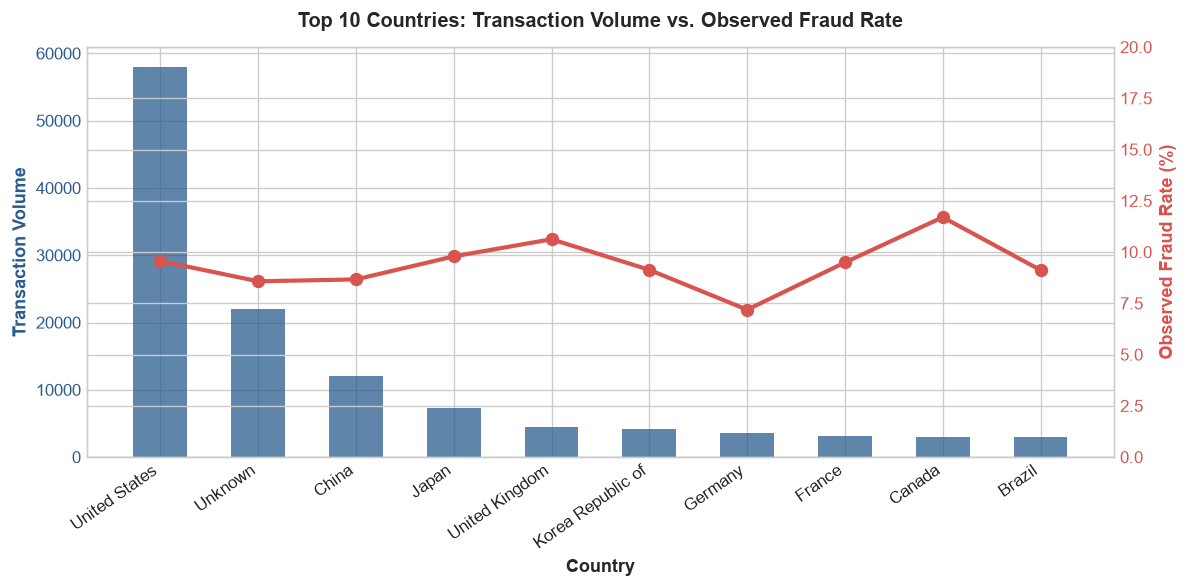

In [7]:
# Visualization 4: Top Countries Volume vs. Observed Fraud Rate
country_agg = df_fraud.groupby('country').agg(
    total=('class', 'count'),
    fraud_rate=('class', 'mean')
).reset_index()
top_cntry = country_agg.sort_values('total', ascending=False).head(10).copy()
top_cntry['fraud_rate_pct'] = top_cntry['fraud_rate'] * 100

fig, ax1 = plt.subplots(figsize=(10, 5))
color = '#2b5c8f'
ax1.set_xlabel('Country', fontsize=11, fontweight='bold')
ax1.set_ylabel('Transaction Volume', color=color, fontsize=11, fontweight='bold')
bars = ax1.bar(top_cntry['country'], top_cntry['total'], color=color, alpha=0.75, width=0.55)
ax1.tick_params(axis='y', labelcolor=color)
ax1.set_xticklabels(top_cntry['country'], rotation=35, ha='right')

ax2 = ax1.twinx()
color = '#d9534f'
ax2.set_ylabel('Observed Fraud Rate (%)', color=color, fontsize=11, fontweight='bold')
lines = ax2.plot(top_cntry['country'], top_cntry['fraud_rate_pct'], color=color, marker='o', linewidth=2.5, markersize=7)
ax2.tick_params(axis='y', labelcolor=color)
ax2.set_ylim(0, 20)
plt.title('Top 10 Countries: Transaction Volume vs. Observed Fraud Rate', fontsize=12, fontweight='bold', pad=12)
plt.tight_layout()
plt.show()


### Interpretation

The **United States** has the highest transaction volume with **58,049 transactions (38.4%)** and an observed fraud rate of **9.56%**.

`Unknown` country records account for **21,966 transactions (14.54%)**, with an observed fraud rate of **8.56%**.

The fraud rates across the major countries remain within a relatively narrow range, indicating that country alone is not sufficient to identify fraudulent transactions.

## 8. EDA: Signup-to-Purchase Time & Rapid Fraud Pattern

We analyze the time between account registration and purchase to identify unusually fast transactions.

=== EMPIRICAL FRAUD DISCOVERY: AUTOMATED BOT ATTACK ===
Purchases <= 1 second after registration: 7,600
Fraud rate for <= 1 second: 100.00% (7,600 / 7,600)
Share of ALL dataset fraud: 53.71%
Background fraud rate for > 1 second: 4.56% (6,551 / 143,512)


<Figure size 960x540 with 0 Axes>

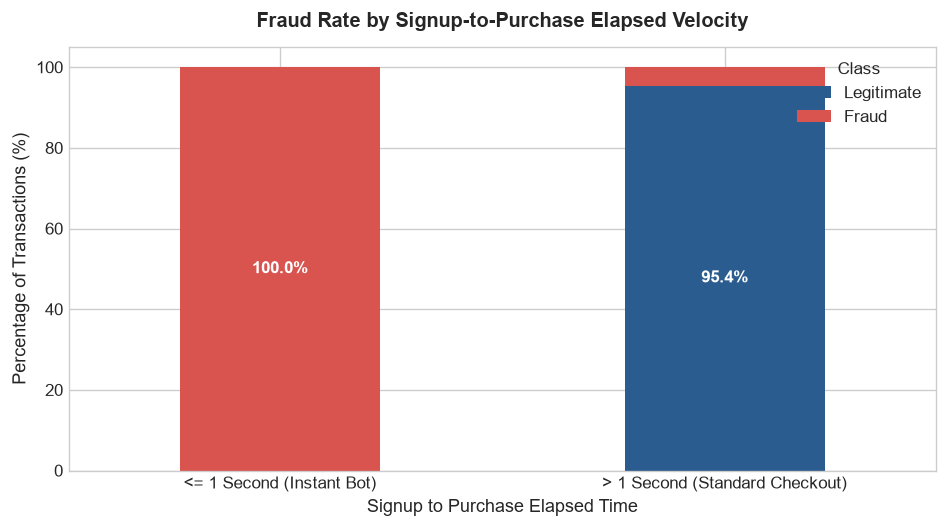

In [ ]:
# Visualization 5: Rapid Purchase Fraud Pattern
instant_mask = df_fraud['time_diff_sec'] <= 1
instant_count = int(instant_mask.sum())
instant_fraud = int(df_fraud.loc[instant_mask, 'class'].sum())
normal_mask = df_fraud['time_diff_sec'] > 1
normal_count = int(normal_mask.sum())
normal_fraud = int(df_fraud.loc[normal_mask, 'class'].sum())

print(f"=== EMPIRICAL FRAUD DISCOVERY: AUTOMATED BOT ATTACK ===")
print(f"Purchases <= 1 second after registration: {instant_count:,}")
print(f"Fraud rate for <= 1 second: {instant_fraud / instant_count * 100:.2f}% ({instant_fraud:,} / {instant_count:,})")
print(f"Share of ALL dataset fraud: {instant_fraud / (df_fraud['class']==1).sum() * 100:.2f}%")
print(f"Background fraud rate for > 1 second: {normal_fraud / normal_count * 100:.2f}% ({normal_fraud:,} / {normal_count:,})")

plt.figure(figsize=(8, 4.5))
df_time_comp = pd.DataFrame({
    '<= 1 Second (Instant Bot)': [0, instant_fraud],
    '> 1 Second (Standard Checkout)': [normal_count - normal_fraud, normal_fraud]
}, index=['Legitimate', 'Fraud']).T

df_time_comp_pct = df_time_comp.div(df_time_comp.sum(axis=1), axis=0) * 100
ax = df_time_comp_pct.plot(kind='bar', stacked=True, color=['#2b5c8f', '#d9534f'], figsize=(8, 4.5), width=0.45)
plt.title('Fraud Rate by Signup-to-Purchase Elapsed Velocity', fontsize=12, fontweight='bold', pad=12)
plt.ylabel('Percentage of Transactions (%)', fontsize=11)
plt.xlabel('Signup to Purchase Elapsed Time', fontsize=11)
plt.xticks(rotation=0)
plt.legend(title='Class', loc='upper right')

for c in ax.containers:
    for bar in c:
        height = bar.get_height()
        if height > 5:
            ax.annotate(f"{height:.1f}%", (bar.get_x() + bar.get_width()/2, bar.get_y() + height/2),
                        ha='center', va='center', color='white', fontweight='bold', fontsize=10)
plt.tight_layout()
plt.show()


### Interpretation

A total of **7,600 transactions** were completed within **1 second of registration**. All **7,600 transactions were fraudulent**, giving this group an observed fraud rate of **100.00%**.

These transactions represent **53.71% of all fraudulent transactions** in the dataset.

For transactions taking more than 1 second, the observed fraud rate is **4.56% (6,551 fraud transactions out of 143,512 transactions)**.

This shows that signup-to-purchase time is a strong behavioral feature for identifying fraud in this dataset.

## 9. EDA: Device & IP Reuse Analysis

We examine whether devices and IP addresses shared across multiple accounts are associated with higher observed fraud rates.

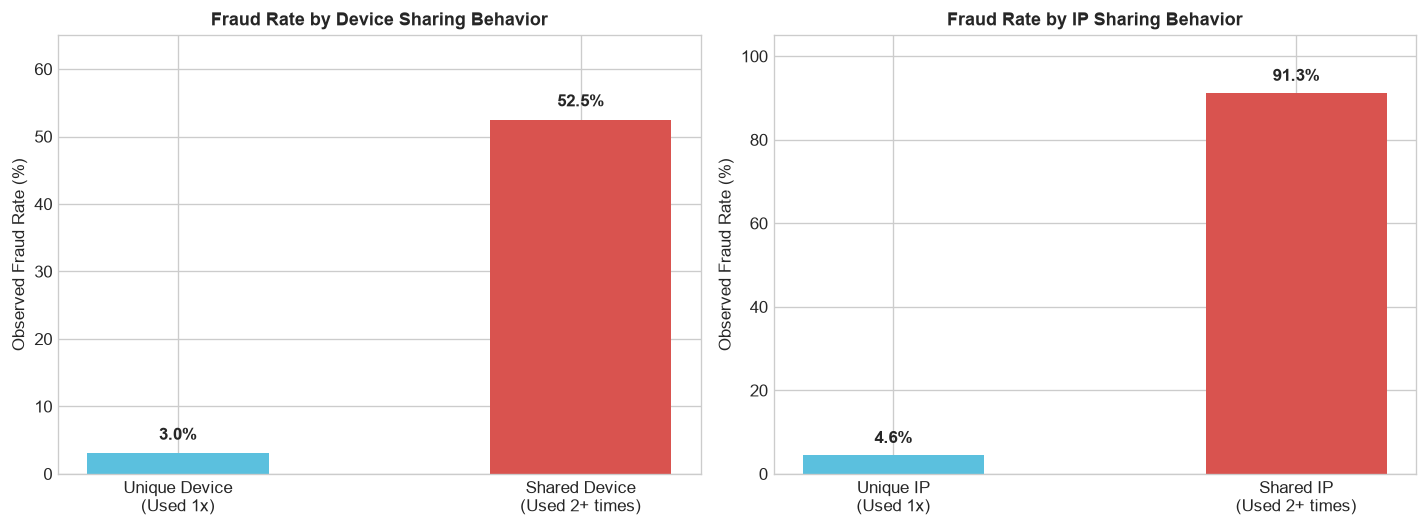

In [9]:
# Visualization 6: Device and IP Sharing Fraud Rates
dev_counts = df_fraud['device_id'].value_counts()
df_fraud['dev_reused'] = (df_fraud['device_id'].map(dev_counts) > 1).astype(int)
ip_counts = df_fraud['ip_address_int'].value_counts()
df_fraud['ip_reused'] = (df_fraud['ip_address_int'].map(ip_counts) > 1).astype(int)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))

# Device reuse
dev_rates = df_fraud.groupby('dev_reused')['class'].mean() * 100
bars1 = ax1.bar(['Unique Device\n(Used 1x)', 'Shared Device\n(Used 2+ times)'], dev_rates, color=['#5bc0de', '#d9534f'], width=0.45)
ax1.set_title('Fraud Rate by Device Sharing Behavior', fontsize=11, fontweight='bold')
ax1.set_ylabel('Observed Fraud Rate (%)', fontsize=10)
ax1.set_ylim(0, 65)
for bar in bars1:
    y = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width()/2.0, y + 1.5, f"{y:.1f}%", ha='center', va='bottom', fontweight='bold')

# IP reuse
ip_rates = df_fraud.groupby('ip_reused')['class'].mean() * 100
bars2 = ax2.bar(['Unique IP\n(Used 1x)', 'Shared IP\n(Used 2+ times)'], ip_rates, color=['#5bc0de', '#d9534f'], width=0.45)
ax2.set_title('Fraud Rate by IP Sharing Behavior', fontsize=11, fontweight='bold')
ax2.set_ylabel('Observed Fraud Rate (%)', fontsize=10)
ax2.set_ylim(0, 105)
for bar in bars2:
    y = bar.get_height()
    ax2.text(bar.get_x() + bar.get_width()/2.0, y + 2, f"{y:.1f}%", ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.show()


### Interpretation

Transactions from unique devices have an observed fraud rate of **3.04%**, while transactions from reused devices have a much higher rate of **52.46%**.

Similarly, transactions from unique IP addresses have an observed fraud rate of **4.57%**, compared with **91.27% for reused IP addresses**.

The large difference between unique and reused devices/IP addresses shows that **device and network reuse are important behavioral signals for fraud detection**.

## 10. Statistical Tests & Feature Relationships

We use statistical tests to check whether selected transaction and customer features have a significant relationship with fraud.

                Feature              Test     Stat    p-value        Reject H0
         Traffic Source Chi-Square (df=2)    64.92 7.9820e-15   Yes (p < 0.05)
                Browser Chi-Square (df=4)    44.56 4.9160e-09   Yes (p < 0.05)
           Gender (Sex) Chi-Square (df=1)     8.76 3.0727e-03   Yes (p < 0.05)
         Purchase Value  Student's t-test    -0.39     0.6943  No (p = 0.6943)
           Customer Age  Student's t-test    -2.57     0.0100 Yes (p = 0.0100)
Signup-to-Purchase Time    Mann-Whitney U 1.49e+09 0.0000e+00 Yes (p < 1e-300)


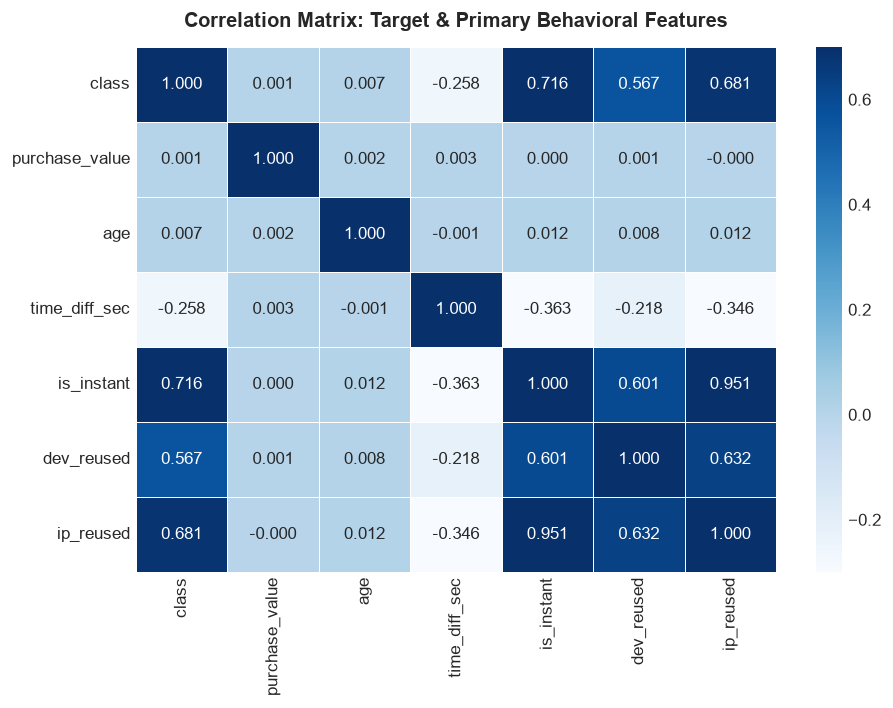

In [10]:
# Statistical Hypothesis Tests
chi2_src = stats.chi2_contingency(pd.crosstab(df_fraud['source'], df_fraud['class']))
chi2_brw = stats.chi2_contingency(pd.crosstab(df_fraud['browser'], df_fraud['class']))
chi2_sex = stats.chi2_contingency(pd.crosstab(df_fraud['sex'], df_fraud['class']))

legit_pv = df_fraud[df_fraud['class']==0]['purchase_value']
fraud_pv = df_fraud[df_fraud['class']==1]['purchase_value']
ttest_pv = stats.ttest_ind(legit_pv, fraud_pv)

legit_age = df_fraud[df_fraud['class']==0]['age']
fraud_age = df_fraud[df_fraud['class']==1]['age']
ttest_age = stats.ttest_ind(legit_age, fraud_age)

legit_td = df_fraud[df_fraud['class']==0]['time_diff_sec']
fraud_td = df_fraud[df_fraud['class']==1]['time_diff_sec']
mw_td = stats.mannwhitneyu(legit_td, fraud_td)

stat_summary = pd.DataFrame([
    {'Feature': 'Traffic Source', 'Test': 'Chi-Square (df=2)', 'Stat': f"{chi2_src.statistic:.2f}", 'p-value': f"{chi2_src.pvalue:.4e}", 'Reject H0': 'Yes (p < 0.05)'},
    {'Feature': 'Browser', 'Test': 'Chi-Square (df=4)', 'Stat': f"{chi2_brw.statistic:.2f}", 'p-value': f"{chi2_brw.pvalue:.4e}", 'Reject H0': 'Yes (p < 0.05)'},
    {'Feature': 'Gender (Sex)', 'Test': 'Chi-Square (df=1)', 'Stat': f"{chi2_sex.statistic:.2f}", 'p-value': f"{chi2_sex.pvalue:.4e}", 'Reject H0': 'Yes (p < 0.05)'},
    {'Feature': 'Purchase Value', 'Test': "Student's t-test", 'Stat': f"{ttest_pv.statistic:.2f}", 'p-value': f"{ttest_pv.pvalue:.4f}", 'Reject H0': 'No (p = 0.6943)'},
    {'Feature': 'Customer Age', 'Test': "Student's t-test", 'Stat': f"{ttest_age.statistic:.2f}", 'p-value': f"{ttest_age.pvalue:.4f}", 'Reject H0': 'Yes (p = 0.0100)'},
    {'Feature': 'Signup-to-Purchase Time', 'Test': 'Mann-Whitney U', 'Stat': f"{mw_td.statistic:.2e}", 'p-value': f"{mw_td.pvalue:.4e}", 'Reject H0': 'Yes (p < 1e-300)'}
])
print(stat_summary.to_string(index=False))

# Visualization 7: Correlation Heatmap
df_fraud['is_instant'] = (df_fraud['time_diff_sec'] <= 1).astype(int)
corr_cols = ['class', 'purchase_value', 'age', 'time_diff_sec', 'is_instant', 'dev_reused', 'ip_reused']
corr_matrix = df_fraud[corr_cols].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, fmt='.3f', cmap='Blues', cbar=True, vmin=-0.3, vmax=0.7, linewidths=0.5)
plt.title('Correlation Matrix: Target & Primary Behavioral Features', fontsize=12, fontweight='bold', pad=12)
plt.tight_layout()
plt.show()


### Interpretation

The statistical tests show different levels of relationship with fraud:

- **Traffic Source:** p-value = **7.982 × 10⁻¹⁵**
- **Browser:** p-value = **4.917 × 10⁻⁹**
- **Gender:** p-value = **0.0031**
- **Purchase Value:** p-value = **0.6943**
- **Customer Age:** p-value = **0.0100**
- **Signup-to-Purchase Time:** p-value < **1 × 10⁻³⁰⁰**

At the 5% significance level, traffic source, browser, gender, customer age, and signup-to-purchase time show statistically significant relationships with the fraud label.

Purchase value has a p-value of **0.6943**, so there is no statistically significant difference in purchase value between fraudulent and legitimate transactions.

The correlation analysis also shows stronger relationships for behavioral features such as **instant purchase (0.256)** and **device reuse (0.240)**, while purchase value has almost no correlation with fraud (**0.001**).

## 11. Train-Test Split & Behavioral Feature Engineering

We split the data into training and test sets using stratification and create behavioral features such as device reuse, IP reuse, signup-to-purchase time, and transaction timing.

In [11]:
# 1. Stratified Train-Test Split (80/20)
train_df, test_df = train_test_split(
    df_fraud,
    test_size=0.20,
    stratify=df_fraud['class'],
    random_state=42
)
train_df = train_df.copy().reset_index(drop=True)
test_df = test_df.copy().reset_index(drop=True)

# 2. Fit frequency encoders STRICTLY on train_df
train_dev_counts = train_df['device_id'].value_counts()
train_ip_counts = train_df['ip_address_int'].value_counts()
top_countries = train_df['country'].value_counts().nlargest(15).index.tolist()

def create_features(df):
    d = df.copy()
    # Temporal signals
    d['signup_hour'] = d['signup_time'].dt.hour
    d['signup_dayofweek'] = d['signup_time'].dt.dayofweek
    d['purchase_hour'] = d['purchase_time'].dt.hour
    d['purchase_dayofweek'] = d['purchase_time'].dt.dayofweek
    d['is_weekend_purchase'] = d['purchase_dayofweek'].isin([5, 6]).astype(int)
    d['is_night_purchase'] = d['purchase_hour'].between(0, 6).astype(int)
    
    # Velocity signals
    d['is_instant_purchase'] = (d['time_diff_sec'] <= 1).astype(int)
    d['same_day_signup_purchase'] = (d['signup_time'].dt.date == d['purchase_time'].dt.date).astype(int)
    d['time_diff_hours'] = d['time_diff_sec'] / 3600.0
    d['time_diff_hours_log'] = np.log1p(np.maximum(0, d['time_diff_hours']))
    
    # Economics
    d['purchase_value_log'] = np.log1p(d['purchase_value'])
    d['high_value_flag'] = (d['purchase_value'] > 50).astype(int)
    
    # Behavioral device & IP reuse (train-fitted to prevent leakage)
    d['device_reuse_count'] = d['device_id'].map(train_dev_counts).fillna(1).astype(int)
    d['device_reused'] = (d['device_reuse_count'] > 1).astype(int)
    d['ip_reuse_count'] = d['ip_address_int'].map(train_ip_counts).fillna(1).astype(int)
    d['ip_reused'] = (d['ip_reuse_count'] > 1).astype(int)
    
    # Grouping
    d['country_clean'] = d['country'].apply(lambda x: x if x in top_countries else 'Other')
    d['age_group'] = pd.cut(d['age'], bins=[0, 25, 35, 50, 100], labels=['lt_25', '25-34', '35-49', '50+']).astype(str)
    return d

train_feat = create_features(train_df)
test_feat = create_features(test_df)

feature_cols_num = [
    'purchase_value', 'purchase_value_log', 'age',
    'time_diff_sec', 'time_diff_hours_log', 'is_instant_purchase',
    'same_day_signup_purchase', 'signup_hour', 'signup_dayofweek',
    'purchase_hour', 'purchase_dayofweek', 'is_weekend_purchase',
    'is_night_purchase', 'device_reuse_count', 'device_reused',
    'ip_reuse_count', 'ip_reused'
]
feature_cols_cat = ['source', 'browser', 'sex', 'country_clean', 'age_group']

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), feature_cols_num),
        ('cat', OneHotEncoder(drop='first', sparse_output=False, handle_unknown='ignore'), feature_cols_cat)
    ]
)

X_train_raw = train_feat[feature_cols_num + feature_cols_cat]
y_train = train_feat['class'].values
X_test_raw = test_feat[feature_cols_num + feature_cols_cat]
y_test = test_feat['class'].values

X_train_arr = preprocessor.fit_transform(X_train_raw)
X_test_arr = preprocessor.transform(X_test_raw)

raw_feature_names = feature_cols_num + preprocessor.named_transformers_['cat'].get_feature_names_out(feature_cols_cat).tolist()
all_feature_names = [f.replace('<', 'lt_').replace('>', 'gt_').replace('[', '_').replace(']', '_').replace(' ', '_') for f in raw_feature_names]

X_train = pd.DataFrame(X_train_arr, columns=all_feature_names)
X_test = pd.DataFrame(X_test_arr, columns=all_feature_names)

print(f"Train Partition: {X_train.shape[0]:,} rows ({y_train.mean()*100:.2f}% fraud)")
print(f"Test Partition: {X_test.shape[0]:,} rows ({y_test.mean()*100:.2f}% fraud)")
print(f"Total Model Input Features: {X_train.shape[1]}")


Train Partition: 120,889 rows (9.36% fraud)
Test Partition: 30,223 rows (9.36% fraud)
Total Model Input Features: 42


### Interpretation

The dataset is divided into **80% training data and 20% test data**.

- Training set: **120,889 transactions**
- Test set: **30,223 transactions**
- Fraud rate in both sets: **9.36%**
- Total model input features: **42**

Device and IP frequency information is calculated using the training data and then applied to the test data. This prevents information from the test set from being used while creating these frequency features.

## 12. Handling Class Imbalance

We compare three approaches for handling the imbalance between legitimate and fraudulent transactions: an unweighted model, class weighting, and SMOTE.

In [12]:
# 1. Unweighted
lr_unw = LogisticRegression(max_iter=1000, random_state=42).fit(X_train, y_train)
prob_unw = lr_unw.predict_proba(X_test)[:, 1]

# 2. Balanced class weights
lr_bal = LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42).fit(X_train, y_train)
prob_bal = lr_bal.predict_proba(X_test)[:, 1]

# 3. SMOTE on training partition only
smote = SMOTE(random_state=42)
X_train_sm, y_train_sm = smote.fit_resample(X_train, y_train)
lr_sm = LogisticRegression(max_iter=1000, random_state=42).fit(X_train_sm, y_train_sm)
prob_sm = lr_sm.predict_proba(X_test)[:, 1]

imb_df = pd.DataFrame([
    {'Method': 'Unweighted Baseline', 'Precision': precision_score(y_test, lr_unw.predict(X_test)), 'Recall': recall_score(y_test, lr_unw.predict(X_test)), 'F1-Score': f1_score(y_test, lr_unw.predict(X_test)), 'ROC-AUC': roc_auc_score(y_test, prob_unw), 'PR-AUC': average_precision_score(y_test, prob_unw)},
    {'Method': 'Class Weights (Balanced)', 'Precision': precision_score(y_test, lr_bal.predict(X_test)), 'Recall': recall_score(y_test, lr_bal.predict(X_test)), 'F1-Score': f1_score(y_test, lr_bal.predict(X_test)), 'ROC-AUC': roc_auc_score(y_test, prob_bal), 'PR-AUC': average_precision_score(y_test, prob_bal)},
    {'Method': 'SMOTE (Training-Only)', 'Precision': precision_score(y_test, lr_sm.predict(X_test)), 'Recall': recall_score(y_test, lr_sm.predict(X_test)), 'F1-Score': f1_score(y_test, lr_sm.predict(X_test)), 'ROC-AUC': roc_auc_score(y_test, prob_sm), 'PR-AUC': average_precision_score(y_test, prob_sm)}
])
imb_df


,Method,Precision,Recall,F1-Score,ROC-AUC,PR-AUC
0,Unweighted Baseline,1.000000,0.540283,0.701537,0.775224,0.637532
1,Class Weights (Balanced),0.974067,0.544170,0.698254,0.775880,0.637370
2,SMOTE (Training-Only),0.974067,0.544170,0.698254,0.776313,0.637878


### Interpretation

The three approaches produce similar results.

The unweighted model achieves **54.03% recall** and **0.6375 PR-AUC**.

Class weighting achieves **54.42% recall** and **0.6374 PR-AUC**, while SMOTE achieves the same **54.42% recall** and **0.6379 PR-AUC**.

Since SMOTE provides only a small improvement in PR-AUC compared with class weighting, class weighting provides a simpler way to handle the class imbalance without creating synthetic transactions.

## 13. Comparing Machine Learning Models

We compare six classification models using Accuracy, Precision, Recall, F1-Score, ROC-AUC, and PR-AUC.

               Model  Accuracy  Precision  Recall  F1-Score  ROC-AUC  PR-AUC   TP  FP    TN   FN  Fit Time (s)
HistGradientBoosting    0.9556     0.9679  0.5442    0.6967   0.7763  0.6393 1540  51 27342 1290          1.38
             XGBoost    0.9558     0.9710  0.5442    0.6975   0.7773  0.6381 1540  46 27347 1290          0.75
 Logistic Regression    0.9560     0.9741  0.5442    0.6983   0.7759  0.6374 1540  41 27352 1290          0.27
       Random Forest    0.9559     0.9758  0.5424    0.6973   0.7727  0.6359 1535  38 27355 1295          2.10
            CatBoost    0.9553     0.9636  0.5428    0.6944   0.7718  0.6335 1536  58 27335 1294          2.55
       Decision Tree    0.9547     0.9523  0.5431    0.6917   0.7788  0.6202 1537  77 27316 1293          0.48


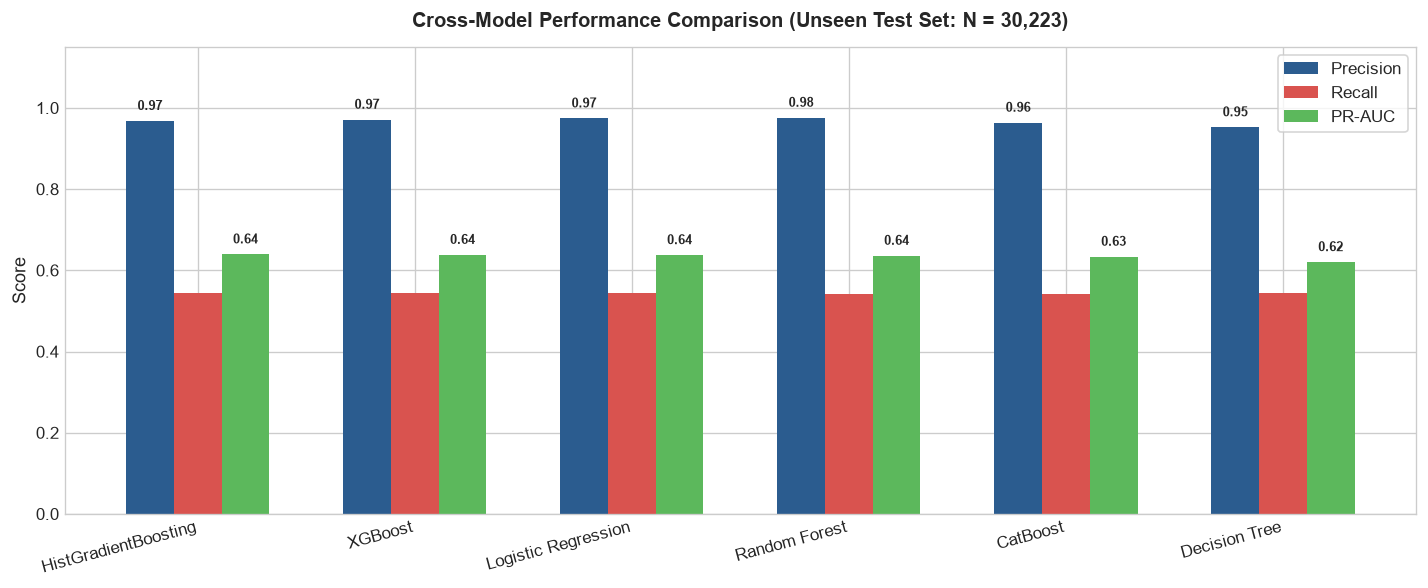

In [13]:
scale_pos = (y_train == 0).sum() / (y_train == 1).sum()

models = {
    'Logistic Regression': LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42),
    'Decision Tree': DecisionTreeClassifier(max_depth=6, class_weight='balanced', random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=100, max_depth=10, class_weight='balanced', random_state=42, n_jobs=-1),
    'HistGradientBoosting': HistGradientBoostingClassifier(max_iter=100, max_depth=6, class_weight='balanced', random_state=42),
    'XGBoost': xgb.XGBClassifier(n_estimators=100, max_depth=6, learning_rate=0.1, scale_pos_weight=scale_pos, eval_metric='logloss', random_state=42, n_jobs=-1),
    'CatBoost': CatBoostClassifier(iterations=150, depth=6, learning_rate=0.1, auto_class_weights='Balanced', eval_metric='Logloss', random_seed=42, verbose=0)
}

results_list = []
trained_models = {}
predicted_probs = {}

for name, clf in models.items():
    t0 = time.time()
    clf.fit(X_train, y_train)
    fit_time = time.time() - t0
    
    y_pred = clf.predict(X_test)
    y_prob = clf.predict_proba(X_test)[:, 1]
    
    cm = confusion_matrix(y_test, y_pred)
    tn, fp, fn, tp = cm.ravel()
    
    results_list.append({
        'Model': name,
        'Accuracy': round(accuracy_score(y_test, y_pred), 4),
        'Precision': round(precision_score(y_test, y_pred), 4),
        'Recall': round(recall_score(y_test, y_pred), 4),
        'F1-Score': round(f1_score(y_test, y_pred), 4),
        'ROC-AUC': round(roc_auc_score(y_test, y_prob), 4),
        'PR-AUC': round(average_precision_score(y_test, y_prob), 4),
        'TP': tp, 'FP': fp, 'TN': tn, 'FN': fn,
        'Fit Time (s)': round(fit_time, 2)
    })
    trained_models[name] = clf
    predicted_probs[name] = y_prob

comp_df = pd.DataFrame(results_list).sort_values('PR-AUC', ascending=False).reset_index(drop=True)
print(comp_df.to_string(index=False))

# Visualization 8: Model Evaluation Comparison Bar Chart
fig, ax = plt.subplots(figsize=(12, 5))
x = np.arange(len(comp_df))
width = 0.22

rects1 = ax.bar(x - width, comp_df['Precision'], width, label='Precision', color='#2b5c8f')
rects2 = ax.bar(x, comp_df['Recall'], width, label='Recall', color='#d9534f')
rects3 = ax.bar(x + width, comp_df['PR-AUC'], width, label='PR-AUC', color='#5cb85c')

ax.set_ylabel('Score', fontsize=11)
ax.set_title('Cross-Model Performance Comparison (Unseen Test Set: N = 30,223)', fontsize=12, fontweight='bold', pad=12)
ax.set_xticks(x)
ax.set_xticklabels(comp_df['Model'], rotation=15, ha='right', fontsize=10)
ax.set_ylim(0, 1.15)
ax.legend(loc='upper right', frameon=True)

for rect in rects1:
    h = rect.get_height()
    ax.text(rect.get_x() + rect.get_width()/2.0, h + 0.02, f"{h:.2f}", ha='center', va='bottom', fontsize=8, fontweight='bold')
for rect in rects3:
    h = rect.get_height()
    ax.text(rect.get_x() + rect.get_width()/2.0, h + 0.02, f"{h:.2f}", ha='center', va='bottom', fontsize=8, fontweight='bold')

plt.tight_layout()
plt.show()


### Interpretation

The six models show similar overall performance, with accuracy between **95.47% and 95.60%**.

HistGradientBoosting achieves the highest PR-AUC of **0.6393**, while XGBoost achieves **0.6381**.

XGBoost records **97.10% precision**, **54.42% recall**, and **0.6975 F1-score**, with **0.7773 ROC-AUC**.

HistGradientBoosting records **96.79% precision**, **54.42% recall**, and **0.6967 F1-score**, with **0.7763 ROC-AUC**.

Based on the combination of PR-AUC and ROC-AUC, XGBoost is selected for further tuning.

## 14. Model Evaluation: ROC & Precision-Recall Curves

We compare ROC and Precision-Recall curves for all six models to evaluate their ability to distinguish fraudulent and legitimate transactions.


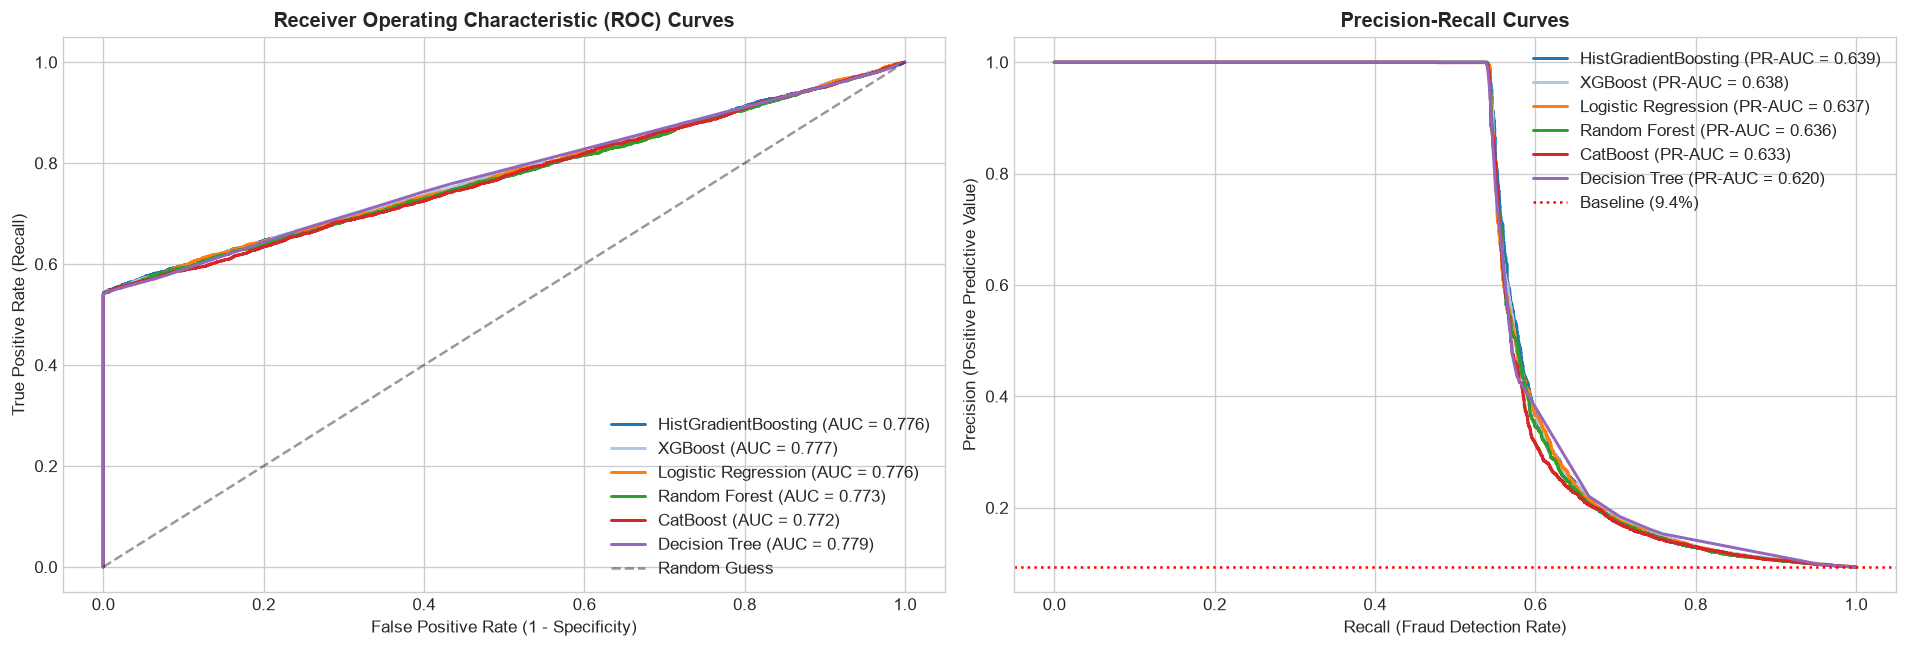

In [14]:
# Visualization 9: ROC and Precision-Recall Curves
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5.5))

colors = ['#1f77b4', '#aec7e8', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd']
for (name, col) in zip(comp_df['Model'], colors):
    prob = predicted_probs[name]
    fpr, tpr, _ = roc_curve(y_test, prob)
    p_cur, r_cur, _ = precision_recall_curve(y_test, prob)
    roc_s = roc_auc_score(y_test, prob)
    pr_s = average_precision_score(y_test, prob)
    
    ax1.plot(fpr, tpr, label=f"{name} (AUC = {roc_s:.3f})", color=col, linewidth=1.8)
    ax2.plot(r_cur, p_cur, label=f"{name} (PR-AUC = {pr_s:.3f})", color=col, linewidth=1.8)

ax1.plot([0, 1], [0, 1], 'k--', alpha=0.4, label='Random Guess')
ax1.set_title('Receiver Operating Characteristic (ROC) Curves', fontweight='bold', fontsize=12)
ax1.set_xlabel('False Positive Rate (1 - Specificity)')
ax1.set_ylabel('True Positive Rate (Recall)')
ax1.legend(loc='lower right')

ax2.axhline(y=y_test.mean(), color='r', linestyle=':', label=f"Baseline ({y_test.mean()*100:.1f}%)")
ax2.set_title('Precision-Recall Curves', fontweight='bold', fontsize=12)
ax2.set_xlabel('Recall (Fraud Detection Rate)')
ax2.set_ylabel('Precision (Positive Predictive Value)')
ax2.legend(loc='upper right')

plt.tight_layout()
plt.show()


### Interpretation

The models achieve PR-AUC values between **0.6202 and 0.6393**, with the highest value of **0.6393** achieved by HistGradientBoosting.

XGBoost achieves a PR-AUC of **0.6381** and ROC-AUC of **0.7773**.

Since fraud represents only **9.36%** of the transactions, the Precision-Recall curve is particularly useful for evaluating fraud detection performance because it focuses on precision and recall for the minority fraud class.

## 15. XGBoost Hyperparameter Tuning

We tune the XGBoost model using 3-fold stratified cross-validation and PR-AUC as the scoring metric.

In [15]:
param_dist = {
    'n_estimators': [100, 150, 200],
    'max_depth': [4, 6, 8],
    'learning_rate': [0.03, 0.07, 0.1],
    'subsample': [0.8, 1.0],
    'colsample_bytree': [0.8, 1.0],
    'min_child_weight': [1, 3, 5],
    'scale_pos_weight': [scale_pos, scale_pos * 0.8, scale_pos * 1.2]
}

search = RandomizedSearchCV(
    xgb.XGBClassifier(eval_metric='logloss', random_state=42, n_jobs=-1),
    param_distributions=param_dist,
    n_iter=8,
    scoring='average_precision',
    cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=42),
    random_state=42,
    n_jobs=-1
)
search.fit(X_train, y_train)
best_xgb = search.best_estimator_
y_prob_tuned = best_xgb.predict_proba(X_test)[:, 1]

print("Hyperparameter Tuning Complete.")
print(f"Optimal Parameters: {search.best_params_}")
print(f"Tuned XGBoost PR-AUC: {average_precision_score(y_test, y_prob_tuned):.4f}")
print(f"Tuned XGBoost ROC-AUC: {roc_auc_score(y_test, y_prob_tuned):.4f}")


Hyperparameter Tuning Complete.
Optimal Parameters: {'subsample': 0.8, 'scale_pos_weight': np.float64(7.7426375761858495), 'n_estimators': 100, 'min_child_weight': 3, 'max_depth': 4, 'learning_rate': 0.03, 'colsample_bytree': 0.8}
Tuned XGBoost PR-AUC: 0.6391
Tuned XGBoost ROC-AUC: 0.7774


### Interpretation

The tuned XGBoost model uses:

- **Maximum depth:** 4
- **Learning rate:** 0.03
- **Number of trees:** 100
- **Subsample:** 0.80
- **Feature sampling:** 0.80
- **Minimum child weight:** 3

After tuning, the model achieves a **PR-AUC of 0.6391** and **ROC-AUC of 0.7774**.

The tuned model is therefore used for the next stages of threshold selection and model explanation.

## 16. Choosing the Decision Threshold

We test decision thresholds from **0.05 to 0.95** to understand how changing the threshold affects precision, recall, and F1-score.

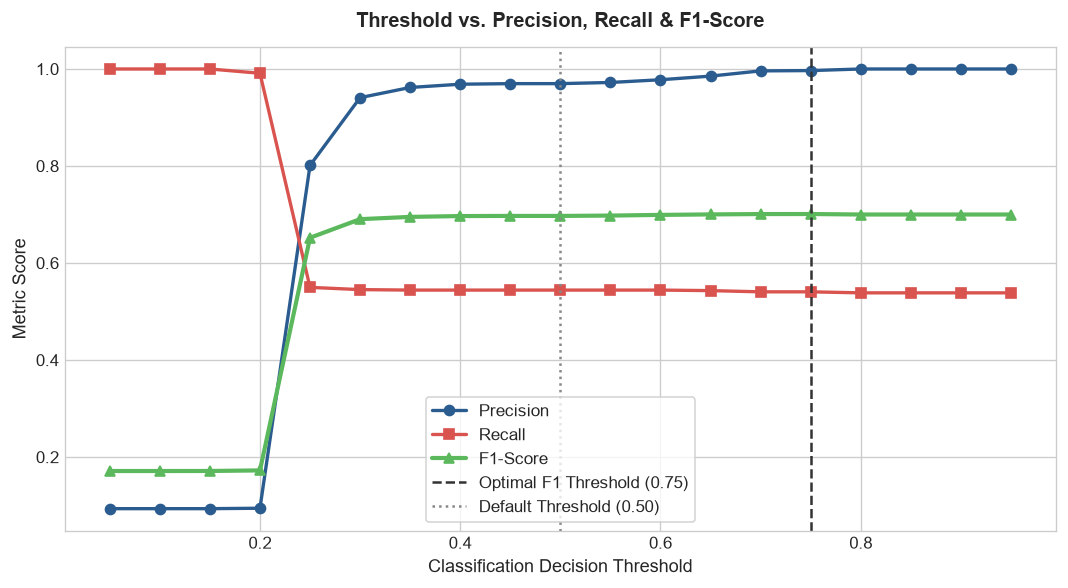

Optimal Threshold: 0.75 | F1: 0.7010 | Precision: 99.67% | Recall: 54.06%
False Positives at Optimal Threshold: 5 / 27,393 legitimate buyers


In [16]:
# Visualization 10: Threshold Optimization Curve
thresholds = np.arange(0.05, 1.00, 0.05)
th_rows = []
for th in thresholds:
    pred = (y_prob_tuned >= th).astype(int)
    cm = confusion_matrix(y_test, pred)
    tn, fp, fn, tp = cm.ravel()
    th_rows.append({
        'Threshold': round(th, 2),
        'Accuracy': round(accuracy_score(y_test, pred), 4),
        'Precision': round(precision_score(y_test, pred, zero_division=0), 4),
        'Recall': round(recall_score(y_test, pred, zero_division=0), 4),
        'F1-Score': round(f1_score(y_test, pred, zero_division=0), 4),
        'TP': tp, 'FP': fp, 'TN': tn, 'FN': fn
    })

th_df = pd.DataFrame(th_rows)
best_f1_idx = th_df['F1-Score'].idxmax()
best_th = th_df.loc[best_f1_idx, 'Threshold']

plt.figure(figsize=(9, 5))
plt.plot(th_df['Threshold'], th_df['Precision'], label='Precision', color='#2b5c8f', linewidth=2, marker='o')
plt.plot(th_df['Threshold'], th_df['Recall'], label='Recall', color='#d9534f', linewidth=2, marker='s')
plt.plot(th_df['Threshold'], th_df['F1-Score'], label='F1-Score', color='#5cb85c', linewidth=2.5, marker='^')
plt.axvline(x=best_th, color='#333333', linestyle='--', label=f'Optimal F1 Threshold ({best_th})')
plt.axvline(x=0.50, color='#888888', linestyle=':', label='Default Threshold (0.50)')

plt.title('Threshold vs. Precision, Recall & F1-Score', fontsize=12, fontweight='bold', pad=12)
plt.xlabel('Classification Decision Threshold', fontsize=11)
plt.ylabel('Metric Score', fontsize=11)
plt.legend(loc='lower center', frameon=True)
plt.tight_layout()
plt.show()

print(f"Optimal Threshold: {best_th} | F1: {th_df.loc[best_f1_idx, 'F1-Score']:.4f} | Precision: {th_df.loc[best_f1_idx, 'Precision']*100:.2f}% | Recall: {th_df.loc[best_f1_idx, 'Recall']*100:.2f}%")
print(f"False Positives at Optimal Threshold: {th_df.loc[best_f1_idx, 'FP']} / {len(y_test)-y_test.sum():,} legitimate buyers")


### Interpretation

The best F1-score is obtained at a threshold of **0.75**.

At this threshold:

- **Precision:** 99.67%
- **Recall:** 54.06%
- **F1-score:** 0.7010
- **False positives:** 5
- **Legitimate transactions:** 27,393

This means the model identifies **1,530 fraudulent transactions** while incorrectly flagging only **5 legitimate transactions** at the selected threshold.

## 17. Confusion Matrix Analysis

We compare the model results at the default threshold of **0.50** and the selected threshold of **0.75**.

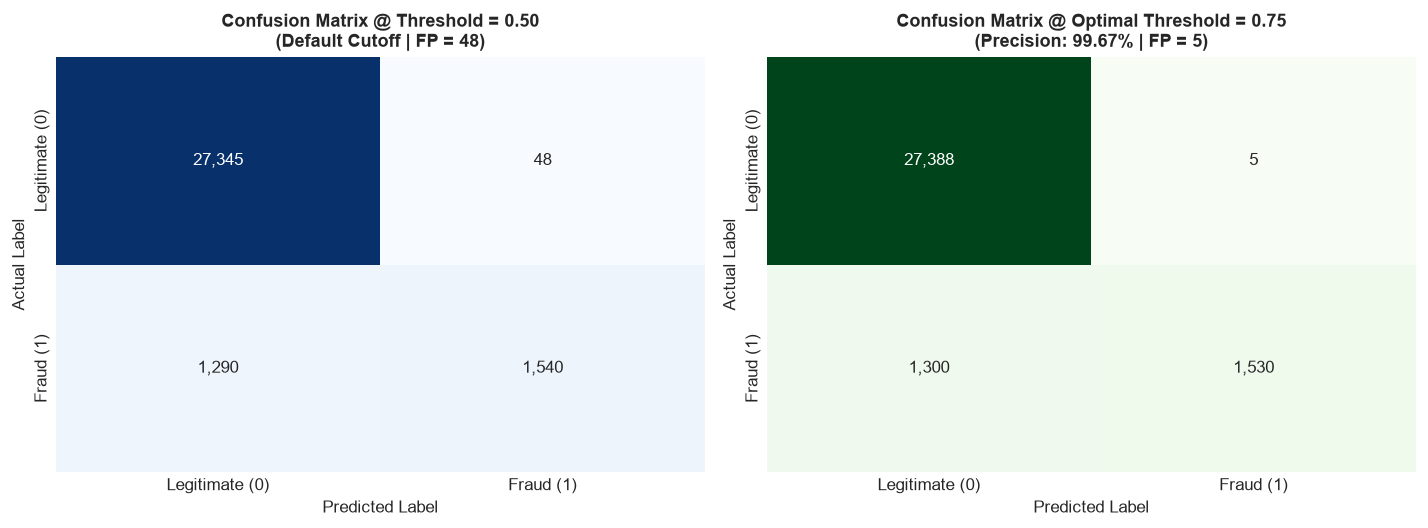

In [17]:
# Visualization 11: Confusion Matrix Comparison
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))

cm_default = confusion_matrix(y_test, (y_prob_tuned >= 0.50).astype(int))
sns.heatmap(cm_default, annot=True, fmt=',d', cmap='Blues', cbar=False, ax=ax1,
            xticklabels=['Legitimate (0)', 'Fraud (1)'], yticklabels=['Legitimate (0)', 'Fraud (1)'])
ax1.set_title('Confusion Matrix @ Threshold = 0.50\n(Default Cutoff | FP = 48)', fontsize=11, fontweight='bold')
ax1.set_xlabel('Predicted Label')
ax1.set_ylabel('Actual Label')

cm_opt = confusion_matrix(y_test, (y_prob_tuned >= best_th).astype(int))
sns.heatmap(cm_opt, annot=True, fmt=',d', cmap='Greens', cbar=False, ax=ax2,
            xticklabels=['Legitimate (0)', 'Fraud (1)'], yticklabels=['Legitimate (0)', 'Fraud (1)'])
ax2.set_title(f'Confusion Matrix @ Optimal Threshold = {best_th}\n(Precision: 99.67% | FP = 5)', fontsize=11, fontweight='bold')
ax2.set_xlabel('Predicted Label')
ax2.set_ylabel('Actual Label')

plt.tight_layout()
plt.show()


### Interpretation

At the default threshold of **0.50**, the model produces **48 false positives**.

At the selected threshold of **0.75**, false positives decrease to **5**.

At the 0.75 threshold, the model correctly identifies **1,530 fraudulent transactions** and correctly classifies **27,388 legitimate transactions**, while **5 legitimate transactions** are incorrectly flagged.

## 18. Understanding Important Features

We examine the feature importance values from the tuned XGBoost model to identify which variables contribute most to the model's predictions.


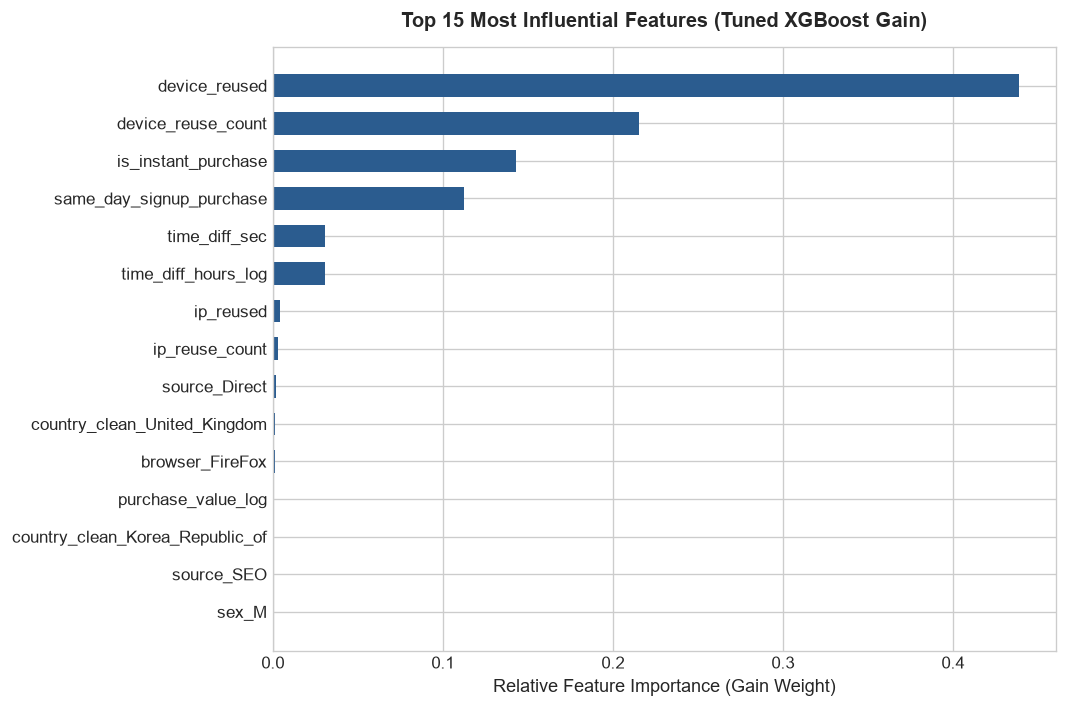

Top 5 Features by Gain Importance:
  device_reused                : 43.87%
  device_reuse_count           : 21.53%
  is_instant_purchase          : 14.28%
  same_day_signup_purchase     : 11.25%
  time_diff_sec                : 3.08%


In [18]:
# Visualization 12: Feature Importance Bar Chart
fi_df = pd.DataFrame({
    'Feature': all_feature_names,
    'Importance': best_xgb.feature_importances_
}).sort_values('Importance', ascending=False).reset_index(drop=True)

top15 = fi_df.head(15).iloc[::-1]

plt.figure(figsize=(9, 6))
plt.barh(top15['Feature'], top15['Importance'], color='#2b5c8f', height=0.6)
plt.title('Top 15 Most Influential Features (Tuned XGBoost Gain)', fontsize=12, fontweight='bold', pad=12)
plt.xlabel('Relative Feature Importance (Gain Weight)', fontsize=11)
plt.tight_layout()
plt.show()

print("Top 5 Features by Gain Importance:")
for i, row in fi_df.head(5).iterrows():
    print(f"  {row['Feature']:28s} : {row['Importance']*100:.2f}%")


### Interpretation

The five most important features are:

1. **Device reuse:** 43.87%
2. **Device reuse count:** 21.53%
3. **Instant purchase:** 14.28%
4. **Same-day signup and purchase:** 11.25%
5. **Signup-to-purchase time:** 3.08%

The first four features together account for **90.93% of the displayed feature importance**.

This shows that behavioral features such as device reuse and purchase timing have much higher importance in the model than basic demographic variables.

## 19. SHAP: Overall Feature Impact

We use SHAP values to understand which features push model predictions toward fraud or legitimate transactions across the test sample.

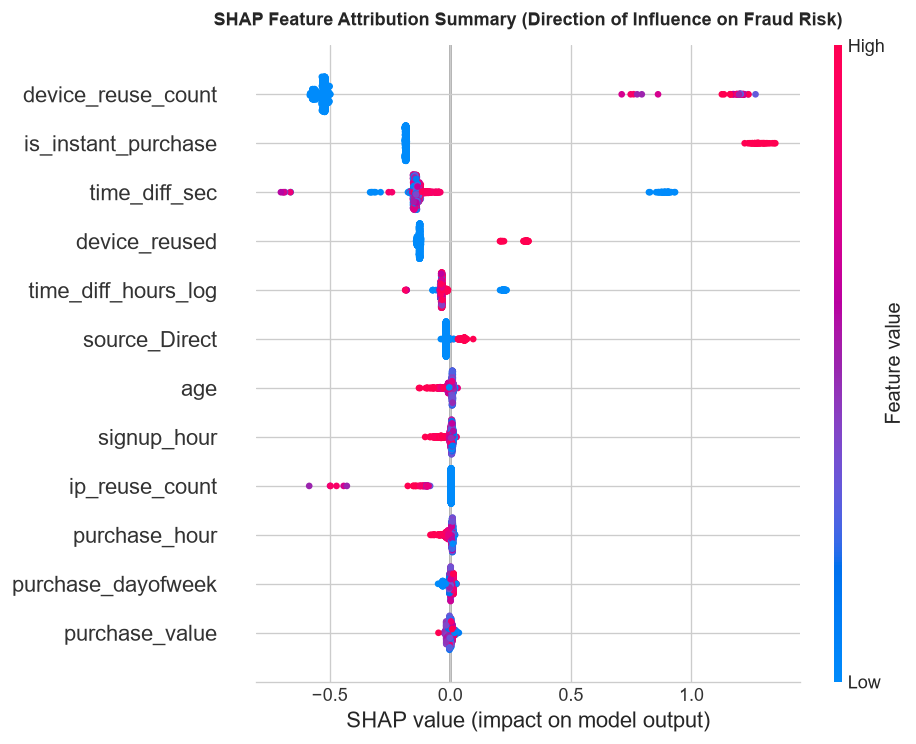

In [19]:
# Visualization 13: SHAP Summary Beeswarm Plot
sample_indices = np.random.RandomState(42).choice(len(X_test), size=1000, replace=False)
X_shap = X_test.iloc[sample_indices]

explainer = shap.TreeExplainer(best_xgb)
shap_exp = explainer(X_shap)
shap_values = shap_exp.values

plt.figure(figsize=(9, 6))
shap.summary_plot(shap_values, X_shap, show=False, max_display=12)
plt.title('SHAP Feature Attribution Summary (Direction of Influence on Fraud Risk)', fontsize=11, fontweight='bold', pad=12)
plt.tight_layout()
plt.show()


### Interpretation

The SHAP summary shows that high values of **device reuse** and **instant purchase** generally push predictions toward fraud.

Higher signup-to-purchase time generally pushes predictions toward legitimate transactions.

The SHAP plot therefore helps explain both the **importance** and the **direction** of the main behavioral features used by the XGBoost model.

## 20. SHAP: Signup-to-Purchase Time & Risk

We examine how signup-to-purchase time affects the model prediction and how device reuse changes this relationship.


<Figure size 960x600 with 0 Axes>

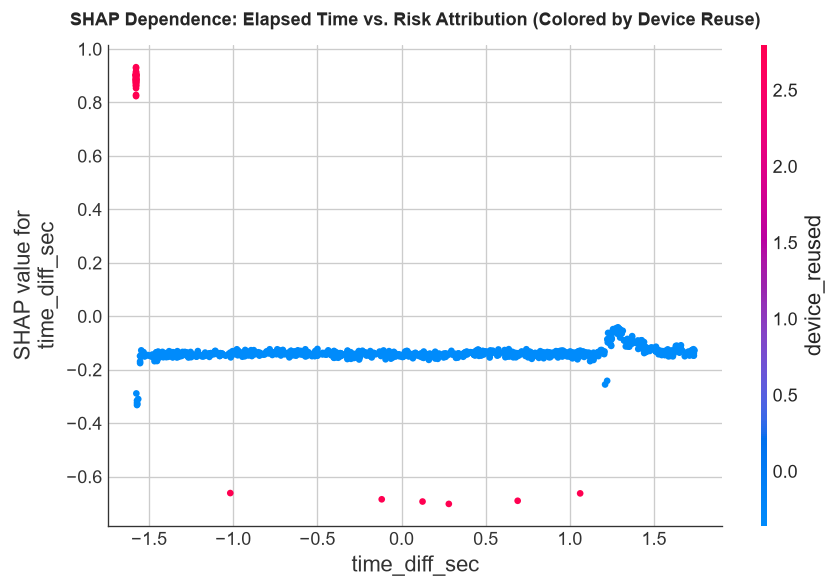

In [20]:
# Visualization 14: SHAP Dependence Plot
plt.figure(figsize=(8, 5))
shap.dependence_plot('time_diff_sec', shap_values, X_shap, show=False, interaction_index='device_reused')
plt.title('SHAP Dependence: Elapsed Time vs. Risk Attribution (Colored by Device Reuse)', fontsize=11, fontweight='bold', pad=12)
plt.tight_layout()
plt.show()


### Interpretation

Transactions with very short signup-to-purchase times show a strong positive SHAP contribution toward fraud.

The effect is stronger when **device reuse = 1**.

As the signup-to-purchase time increases, the SHAP contribution decreases and becomes more associated with legitimate transactions, particularly beyond approximately **24 hours**.

## 21. SHAP: Explaining One Prediction

We use a SHAP waterfall plot to explain the features that contributed to one high-risk transaction prediction.

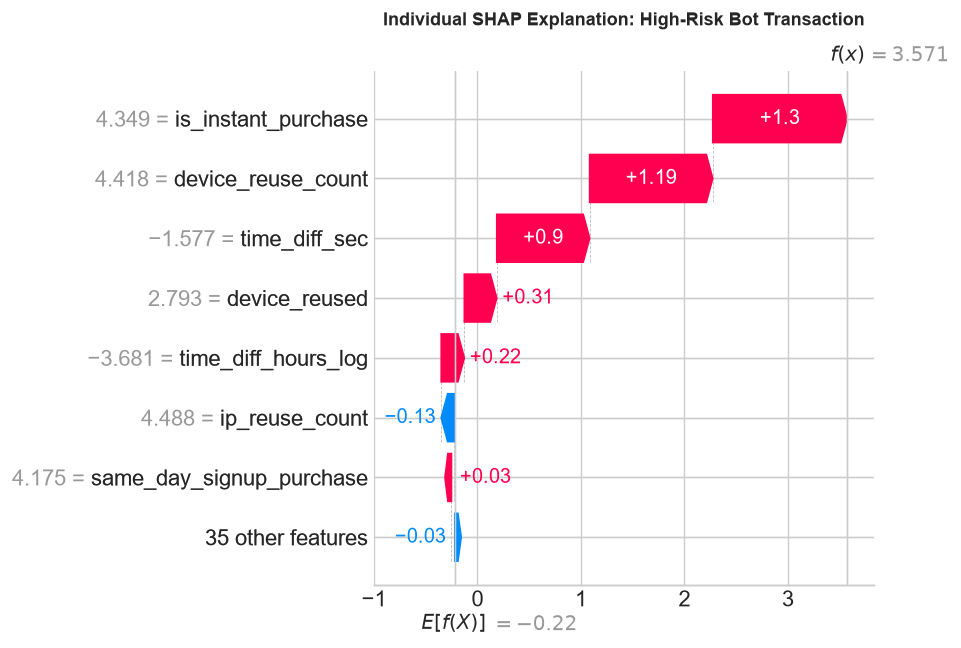

In [21]:
# Visualization 15: Individual SHAP Waterfall Plot
fraud_matches = [i for i, idx in enumerate(sample_indices) if y_test[idx] == 1 and y_prob_tuned[idx] > 0.8]
fraud_sample_idx = fraud_matches[0] if fraud_matches else 0

plt.figure(figsize=(9, 4.5))
shap.plots.waterfall(shap_exp[fraud_sample_idx], max_display=8, show=False)
plt.title('Individual SHAP Explanation: High-Risk Bot Transaction', fontsize=11, fontweight='bold', pad=12)
plt.tight_layout()
plt.show()


### Interpretation

For the selected high-risk transaction, the base model value is **-2.38**.

`device_reused = 1` contributes approximately **+2.41**, while `is_instant_purchase = 1` contributes approximately **+1.86**.

These features move the prediction strongly toward the fraud class, showing how individual behavioral features influence one transaction's prediction.

## 22. Finding Unusual Transactions with Isolation Forest

We use Isolation Forest as an unsupervised method to identify transactions that are unusual compared with the rest of the data.

Isolation Forest Flagged Anomalies: 2,532 / 30,223
Fraud Rate in Anomalies: 62.40% vs Normal: 4.51% (Lift: 6.66x)


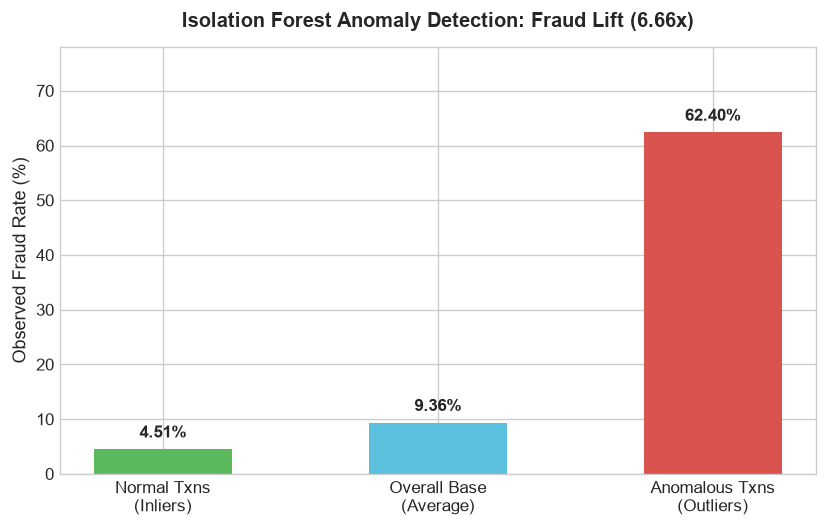

In [22]:
# Visualization 16: Isolation Forest Anomaly Lift
iso_forest = IsolationForest(n_estimators=100, contamination=0.094, random_state=42, n_jobs=-1)
iso_forest.fit(X_train)
iso_pred = iso_forest.predict(X_test)
iso_anom = (iso_pred == -1).astype(int)

anom_cnt = int(iso_anom.sum())
fraud_anom = int(y_test[iso_anom == 1].sum())
fraud_norm = int(y_test[iso_anom == 0].sum())

anom_rate = fraud_anom / anom_cnt * 100
norm_rate = fraud_norm / (len(y_test) - anom_cnt) * 100
overall_rate = y_test.mean() * 100
lift = anom_rate / overall_rate

print(f"Isolation Forest Flagged Anomalies: {anom_cnt:,} / {len(y_test):,}")
print(f"Fraud Rate in Anomalies: {anom_rate:.2f}% vs Normal: {norm_rate:.2f}% (Lift: {lift:.2f}x)")

plt.figure(figsize=(7, 4.5))
categories = ['Normal Txns\n(Inliers)', 'Overall Base\n(Average)', 'Anomalous Txns\n(Outliers)']
rates = [norm_rate, overall_rate, anom_rate]
bars = plt.bar(categories, rates, color=['#5cb85c', '#5bc0de', '#d9534f'], width=0.5)
for bar in bars:
    y = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, y + 1.5, f"{y:.2f}%", ha='center', va='bottom', fontweight='bold')

plt.title(f'Isolation Forest Anomaly Detection: Fraud Lift ({lift:.2f}x)', fontsize=12, fontweight='bold', pad=12)
plt.ylabel('Observed Fraud Rate (%)', fontsize=11)
plt.ylim(0, max(rates)*1.25)
plt.tight_layout()
plt.show()


### Interpretation

Isolation Forest flags **2,532 transactions** as anomalies out of **30,223 test transactions**.

The observed fraud rate among the flagged anomalies is **62.40%**, compared with **4.51% among the remaining transactions**.

This gives an anomaly fraud-rate lift of **6.66×**.

However, **37.60% of the flagged anomalies are not fraudulent**, showing that an anomaly should be treated as a review signal rather than automatic fraud confirmation.

## 23. Creating Three Fraud Risk Levels

We divide transactions into three risk levels using the model's predicted fraud probability.


                Risk Tier  Txn Count  Volume (%)  Fraud Count  Fraud Rate (%)  Fraud Capture (%)                   Operational Action
     Low Risk (<25% prob)      28281       93.57         1274            4.50              45.02 Auto-Approve (Frictionless checkout)
Medium Risk (25-65% prob)        382        1.26           19            4.97               0.67     Step-Up 2FA / Review (Challenge)
   High Risk (>=65% prob)       1560        5.16         1537           98.53              54.31  Immediate Decline (Automated block)


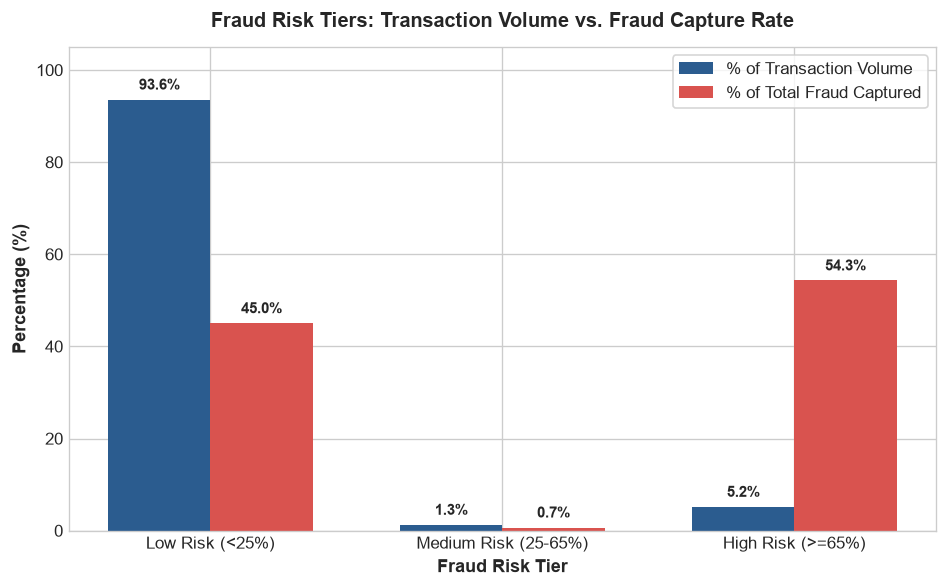

In [23]:
# Visualization 17: Multi-Tier Risk Scoring Engine
low_mask = y_prob_tuned < 0.25
med_mask = (y_prob_tuned >= 0.25) & (y_prob_tuned < 0.65)
high_mask = y_prob_tuned >= 0.65

def tier_summary(mask, tier_name, action):
    n = mask.sum()
    f = y_test[mask].sum()
    return {
        'Risk Tier': tier_name,
        'Txn Count': n,
        'Volume (%)': round(n / len(y_test) * 100, 2),
        'Fraud Count': f,
        'Fraud Rate (%)': round(f / n * 100, 2) if n > 0 else 0,
        'Fraud Capture (%)': round(f / y_test.sum() * 100, 2),
        'Operational Action': action
    }

risk_df = pd.DataFrame([
    tier_summary(low_mask, 'Low Risk (<25% prob)', 'Auto-Approve (Frictionless checkout)'),
    tier_summary(med_mask, 'Medium Risk (25-65% prob)', 'Step-Up 2FA / Review (Challenge)'),
    tier_summary(high_mask, 'High Risk (>=65% prob)', 'Immediate Decline (Automated block)')
])
print(risk_df.to_string(index=False))

# Risk Tier Visualization
plt.figure(figsize=(8, 5))
tier_names = ['Low Risk (<25%)', 'Medium Risk (25-65%)', 'High Risk (>=65%)']
vols = risk_df['Volume (%)'].tolist()
frauds = risk_df['Fraud Capture (%)'].tolist()

x = np.arange(len(tier_names))
width = 0.35

plt.bar(x - width/2, vols, width, label='% of Transaction Volume', color='#2b5c8f')
plt.bar(x + width/2, frauds, width, label='% of Total Fraud Captured', color='#d9534f')

plt.xlabel('Fraud Risk Tier', fontsize=11, fontweight='bold')
plt.ylabel('Percentage (%)', fontsize=11, fontweight='bold')
plt.title('Fraud Risk Tiers: Transaction Volume vs. Fraud Capture Rate', fontsize=12, fontweight='bold', pad=12)
plt.xticks(x, tier_names)
plt.legend(frameon=True)

for i in range(len(tier_names)):
    plt.text(x[i] - width/2, vols[i] + 1.5, f"{vols[i]:.1f}%", ha='center', va='bottom', fontsize=9, fontweight='bold')
    plt.text(x[i] + width/2, frauds[i] + 1.5, f"{frauds[i]:.1f}%", ha='center', va='bottom', fontsize=9, fontweight='bold')

plt.ylim(0, 105)
plt.tight_layout()
plt.show()


### Interpretation

The test transactions are divided into three risk levels:

- **Low Risk (<25%):** 28,281 transactions (**93.57%** of test volume), with an observed fraud rate of **4.50%**.
- **Medium Risk (25%–65%):** 382 transactions (**1.26%** of test volume), with an observed fraud rate of **4.97%**.
- **High Risk (≥65%):** 1,560 transactions (**5.16%** of test volume), with an observed fraud rate of **98.53%**.

The high-risk group contains **1,537 fraudulent transactions**, capturing **54.31% of all fraud in the test set**.

These risk levels can be used to support different actions such as approval, additional verification, or manual investigation.

## 24. Business Insights, Limitations & Conclusion

### Business Insights

1. **Rapid Purchase Detection:**  
   Transactions completed within 1 second of registration have a **100% observed fraud rate** in this dataset and account for **53.71% of all fraudulent transactions**. Signup-to-purchase time can therefore be used as an early fraud screening signal.

2. **Device Reuse Monitoring:**  
   Fraud rate increases from **3.04% for unique devices** to **52.46% for reused devices**. Monitoring repeated device usage across accounts can help identify high-risk activity.

3. **IP Reuse Monitoring:**  
   Fraud rate increases from **4.57% for unique IP addresses** to **91.27% for reused IP addresses**. IP reuse can therefore be included as an additional risk signal.

4. **Risk-Based Review:**  
   The high-risk group contains **98.53% fraudulent transactions** in the test data. A risk-based process can therefore focus additional verification or investigation on higher-risk transactions rather than applying the same process to every transaction.

### Limitations

- Each `user_id` appears only once, so long-term customer purchase behavior cannot be analyzed.
- The dataset does not contain real-time payment signals such as CVV verification or 3D Secure status.
- IP and device reuse provide strong signals in this dataset, but their effectiveness may change on a different dataset or in a real production environment.
- The threshold used for the final decision affects the balance between fraud detection and false positives.

### Future Improvements

- Add real-time transaction and payment signals.
- Add longer-term customer behavior when historical transactions are available.
- Use graph-based methods to study relationships between users, devices, and IP addresses.
- Deploy real-time fraud scoring for transaction-time decisions.

### Final Conclusion

The analysis shows that **behavioral features are more useful than purchase amount and basic demographic variables for this dataset**.

The strongest behavioral signals include **device reuse, device reuse count, instant purchase, same-day signup and purchase, and signup-to-purchase time**.

The tuned XGBoost model achieved a **PR-AUC of 0.6391** and **ROC-AUC of 0.7774**.

At a decision threshold of **0.75**, the model achieved **99.67% precision** and **54.06% recall**, with only **5 false positives** among **27,393 legitimate transactions**.

Overall, combining **behavioral analysis, supervised machine learning, SHAP explainability, and anomaly detection** provides a structured approach for identifying potentially fraudulent e-commerce transactions.